# make_moons (scikit-learn): clustering

1,000 synthetic points on two interleaved half circles (scikit-learn `make_moons`), standardized. Non-convex shapes of even density: the case density methods should handle (report dataset D1).

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/make_moons_results.csv` and `make_moons_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "make_moons"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

scikit-learn make_moons: 1000 points, noise 0.07, seed 42. Standardized.
1,000 points, 2 features, classes: 2


,x1,x2
count,1000.00,1000.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.90,-1.84
25%,-0.62,-0.94
50%,0.03,-0.03
75%,0.63,0.92
max,1.94,1.78


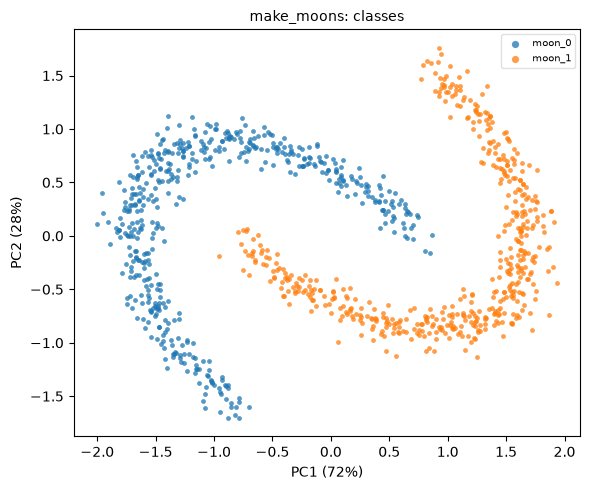

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/make_moons_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save

x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 2, label-free choice: 2


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari,ari
0,2,839.430,0.495,0.356,0.139,0.812,495,505,1.000,1.000,0.481
1,3,615.413,0.447,0.373,0.074,0.890,242,463,0.994,0.978,0.394
2,4,412.115,0.434,0.368,0.066,0.921,219,275,0.990,0.971,0.298
3,5,302.099,0.465,0.368,0.097,0.751,150,235,0.969,0.922,0.304
4,6,232.135,0.488,0.394,0.095,0.664,135,222,0.997,0.995,0.333
5,7,188.403,0.488,0.397,0.091,0.670,108,215,0.982,0.967,0.294
6,8,144.911,0.489,0.393,0.096,0.656,106,146,0.960,0.905,0.250
7,9,120.407,0.493,0.398,0.096,0.613,79,144,0.979,0.901,0.226
8,10,97.408,0.496,0.405,0.091,0.585,77,139,0.941,0.850,0.207


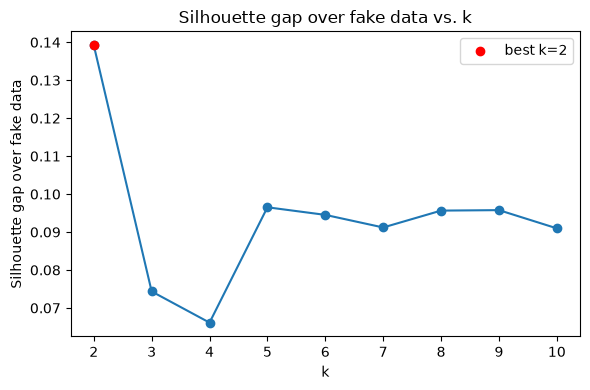

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/make_moons_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save

fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),839.43,7.0,0.006
K-Means,839.43,5.0,0.007


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

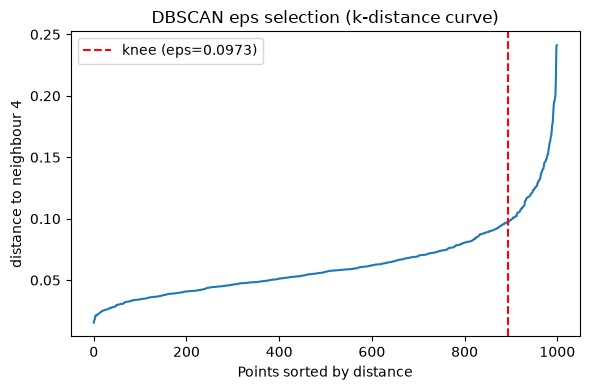

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/make_moons_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save

min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=0.0486, min_samples=4, rule satisfied: True


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,0.038,3,0.50,101,0.504,0.013,0.574,0.005,False
1,0.057,3,0.75,65,0.218,0.052,0.333,0.034,True
2,0.076,3,1.00,26,0.075,0.180,-0.050,0.180,True
3,0.095,3,1.25,8,0.037,0.417,-0.034,0.615,True
4,0.114,3,1.50,2,0.021,0.496,0.394,0.959,True
5,0.152,3,2.00,2,0.007,0.497,0.393,0.986,True
6,0.229,3,3.00,2,0.000,0.500,0.387,1.000,True
7,0.305,3,4.00,2,0.000,0.500,0.387,1.000,True
8,0.049,4,0.50,72,0.471,0.018,0.523,0.009,True
9,0.073,4,0.75,23,0.136,0.171,0.176,0.140,True


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=100, min_samples=None, rule satisfied: True


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,5,NaN,2,0.000,0.500,0.387,1.000,True
1,5,5.0,2,0.000,0.500,0.387,1.000,True
2,5,10.0,2,0.000,0.500,0.387,1.000,True
3,10,NaN,2,0.000,0.500,0.387,1.000,True
4,10,5.0,2,0.000,0.500,0.387,1.000,True
5,10,10.0,2,0.000,0.500,0.387,1.000,True
6,15,NaN,2,0.000,0.500,0.387,1.000,True
7,15,5.0,2,0.000,0.500,0.387,1.000,True
8,15,10.0,2,0.000,0.500,0.387,1.000,True
9,20,NaN,2,0.000,0.500,0.387,1.000,True


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=2, covariance_type=tied, label-free: n_components=9, covariance_type=full


covariance_type,diag,full,spherical,tied
n_components,,,,
2,-5253.5,-5191.6,-5244.3,-5171.0
3,-4851.6,-4705.4,-5113.2,-5183.0
4,-4850.0,-4180.4,-5085.7,-4930.9
5,-4357.7,-4095.1,-4890.7,-4921.8
6,-4056.7,-3548.5,-4852.4,-4774.2
7,-3955.6,-3418.4,-4727.7,-4663.0
8,-3864.5,-3360.3,-4571.5,-4423.5
9,-3767.6,-3325.4,-4468.2,-4294.1
10,-3648.9,-3353.6,-4314.2,-4144.2


## 7. Clustering with Spectral

Spectral clustering at the K-Means k: an RBF affinity on Wine, a 10-nearest-neighbour graph elsewhere
(`run.SPECTRAL_AFFINITY_BY_DATASET`). A dense RBF affinity needs memory quadratic in the number of
points, so it is skipped on large data; the nearest-neighbour graph is sparse and runs at any size.

In [12]:
if run.is_too_large(ds, "Spectral"):
    print(f"skipping Spectral: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_DENSE_SPECTRAL:,}")
else:
    selections["Spectral"] = run.select_method(ds, "Spectral", selections)
    results["Spectral"] = run.fit_method(ds, "Spectral", selections["Spectral"])
    print(f"Spectral: {run.format_params(selections['Spectral'].params)}")

Spectral: n_clusters=2, affinity=nearest_neighbors


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores. The null columns refit each
method at its setting on a copy with every column shuffled: a silhouette near the null one means the
clusters are no stronger than on data without structure.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = [
    "method",
    "params",
    "n_clusters",
    "noise_fraction",
    "largest_cluster_share",
    "silhouette",
    "davies_bouldin",
    "dbcv",
    "ari",
    "nmi",
    "fit_seconds",
    "null_silhouette",
]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,dbcv,ari,nmi,fit_seconds,null_silhouette
0,K-Means (random init),n_clusters=2,2,0.000,0.505,0.495,0.812,-0.710,0.481,0.383,0.006,0.353
1,K-Means,n_clusters=2,2,0.000,0.505,0.495,0.812,-0.710,0.481,0.383,0.007,0.353
2,DBSCAN,"eps=0.0486, min_samples=4",72,0.471,0.018,0.523,0.565,0.227,0.009,0.205,0.003,0.822
3,HDBSCAN,"min_cluster_size=100, min_samples=None",2,0.156,0.424,0.529,0.735,0.465,0.709,0.676,0.018,NaN
4,GMM,"n_components=2, covariance_type=tied",2,0.000,0.500,0.495,0.812,-0.715,0.501,0.400,0.008,0.353
5,Spectral,"n_clusters=2, affinity=nearest_neighbors",2,0.000,0.500,0.387,1.023,0.472,1.000,1.000,0.014,0.319


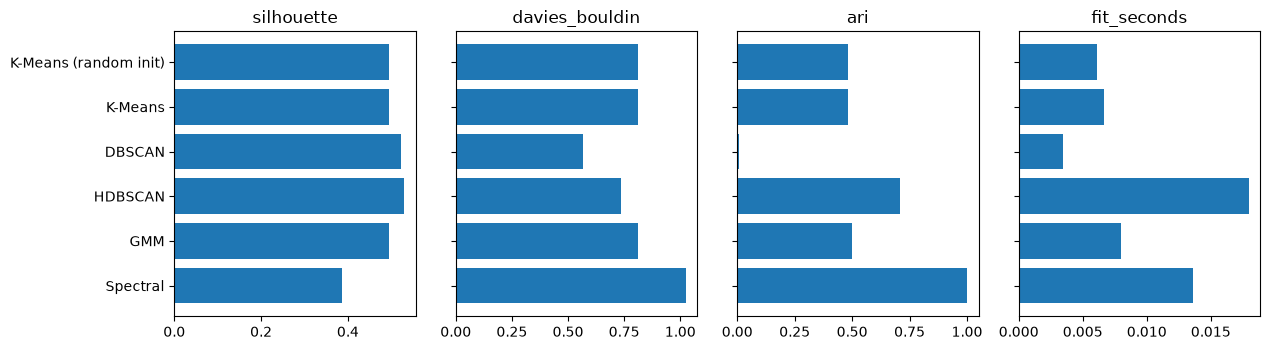

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/make_moons_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save

metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

## 9. Visualization

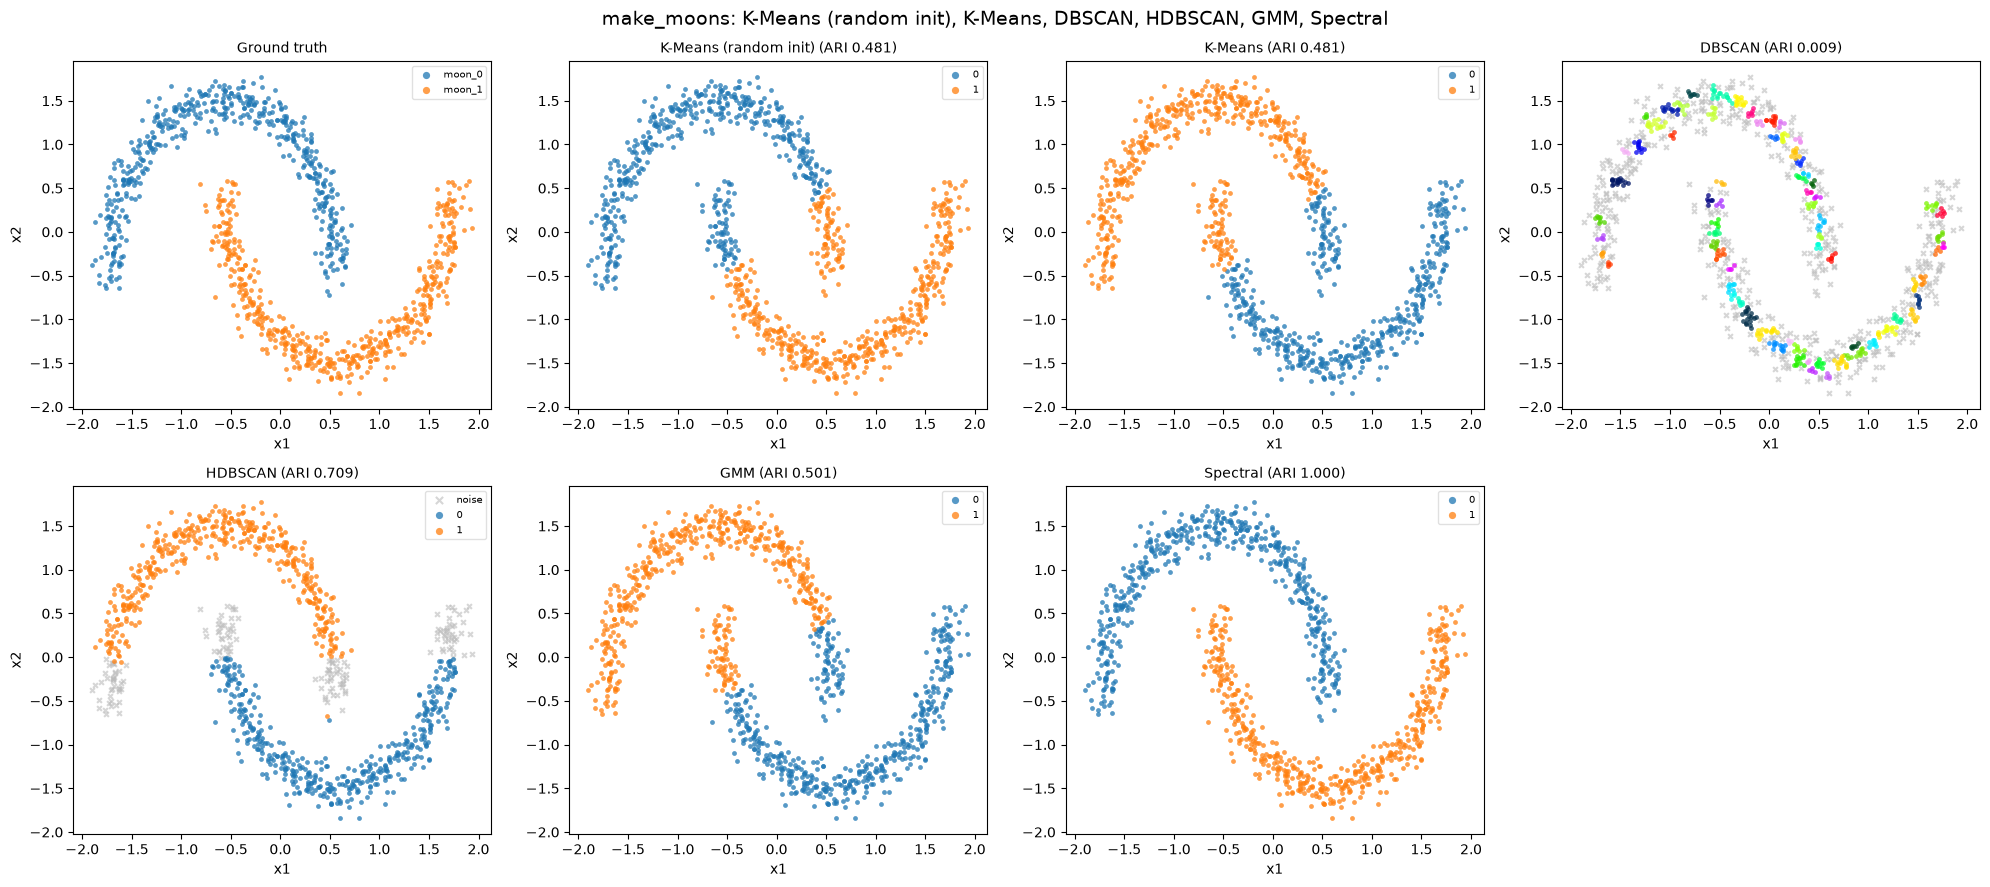

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/make_moons_clusters.png')

In [15]:
from sc4020.generate_figures import show_and_save

fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")